
# Phase 9: Feature Normalisation and Training Pipeline

## 9.1 Understanding Feature Normalisation

The five input features in the battery dataset have different numerical scales. Feature normalisation helps the neural network train more consistently by bringing the input features to comparable scales.

We use standardisation:

X_normalised = (X - mean) / standard_deviation

The mean and standard deviation are calculated using only the training dataset. The same values are then applied to the validation dataset to prevent data leakage.

Only the input features are normalised. The target variable, days_left, remains unchanged.



## 9.2 Loading and Inspecting the Dataset

Load the Team 13 battery dataset and identify the five input features and the target variable.

Before applying normalisation, inspect the dataset dimensions, column names, and data types.


In [1]:

import pandas as pd
import numpy as np

df = pd.read_csv("data/team_13_train.csv")

FEATURES = [
    "battery_v",
    "temp_c",
    "rings_per_day",
    "wifi_rssi_dbm",
    "age_months"
]

TARGET = "days_left"

print("Dataset shape:", df.shape)
print("\nInput features:")
print(df[FEATURES].head())

print("\nTarget:")
print(df[TARGET].head())

print("\nData types:")
print(df[FEATURES + [TARGET]].dtypes)


Dataset shape: (2000, 6)

Input features:
   battery_v  temp_c  rings_per_day  wifi_rssi_dbm  age_months
0      3.767    18.2             17            -85          35
1      4.184    24.3              4            -63          15
2      3.585    18.7             16            -50          35
3      3.480    10.0             11            -56           3
4      3.366    28.7             10            -47           0

Target:
0     19.1
1    221.7
2     14.8
3     10.9
4      2.6
Name: days_left, dtype: float64

Data types:
battery_v        float64
temp_c           float64
rings_per_day      int64
wifi_rssi_dbm      int64
age_months         int64
days_left        float64
dtype: object



### Observation – Dataset Inspection

The Team 13 dataset contains 2,000 rows and 6 columns. Five columns are input features and days_left is the target variable.

All selected columns contain numerical data. The input features have mixed numerical data types (float64 and int64), which will be converted to float32 during model preparation.

The dataset is successfully loaded and ready for the train-validation split.



## 9.3 Preparing Training and Validation Data

Before applying feature normalisation, the dataset is divided into training and validation sets.

A reproducible random split is used, with 80% of the data allocated for training and 20% for validation.

The same random seed (0) and splitting procedure used in `train.py` are followed to ensure consistency between the notebook experiments and the actual training pipeline.

### Dataset Split

- **Training set:** 80% of the cleaned dataset (1,600 rows).
- **Validation set:** 20% of the cleaned dataset (400 rows).

### Input and Target Separation

The five input features are separated from the target variable, `days_left`.

- `X`: Training input features.
- `y`: Training target values.
- `Xv`: Validation input features.
- `yv`: Validation target values.

All input features and target arrays are converted to NumPy float32 for compatibility with PyTorch.

### Important Consideration

The validation dataset is kept separate from the training process. Mean and standard deviation values for normalisation will be calculated using only the training data and then applied to both datasets.

This prevents data leakage and ensures a fair evaluation of the model on unseen validation data.


In [2]:

# Reproduce the same cleaning and train-validation split as train.py

bad = (
    (df["rings_per_day"] < 0) |
    (df["age_months"] < 0) |
    (df["days_left"] < 0)
)

cleaned_df = df.loc[~bad].copy()

rng = np.random.default_rng(0)

idx = rng.permutation(len(cleaned_df))
n_val = len(cleaned_df) // 5

val = cleaned_df.iloc[idx[:n_val]]
tr = cleaned_df.iloc[idx[n_val:]]

X = tr[FEATURES].to_numpy(np.float32)
y = tr[TARGET].to_numpy(np.float32)

Xv = val[FEATURES].to_numpy(np.float32)
yv = val[TARGET].to_numpy(np.float32)

print("Training rows:", len(tr))
print("Validation rows:", len(val))

print("\nTraining input shape:", X.shape)
print("Training target shape:", y.shape)

print("\nValidation input shape:", Xv.shape)
print("Validation target shape:", yv.shape)


Training rows: 1600
Validation rows: 400

Training input shape: (1600, 5)
Training target shape: (1600,)

Validation input shape: (400, 5)
Validation target shape: (400,)



## 9.4 Calculating Mean and Standard Deviation

Before standardising the input features, the mean and standard deviation of each feature are calculated using only the training dataset.

- Mean (μ): Represents the average value of a feature.
- Standard deviation (σ): Measures how much the feature values vary around the mean.

These statistics are calculated independently for all five input features.

Only the training data is used for these calculations to prevent data leakage from the validation dataset.

The calculated mean and standard deviation will later be used to standardise both training and validation inputs.


In [3]:

# Calculate statistics using training data only

mu = X.mean(axis=0)
sd = X.std(axis=0)

print("Feature means:")
for feature, value in zip(FEATURES, mu):
    print(f"{feature}: {value:.4f}")

print("\nFeature standard deviations:")
for feature, value in zip(FEATURES, sd):
    print(f"{feature}: {value:.4f}")


Feature means:
battery_v: 3.7598
temp_c: 27.3684
rings_per_day: 7.8750
wifi_rssi_dbm: -66.1062
age_months: 17.9419

Feature standard deviations:
battery_v: 0.3499
temp_c: 11.0191
rings_per_day: 5.6271
wifi_rssi_dbm: 12.5634
age_months: 10.5267



### Observation – Training Statistics

The mean and standard deviation were successfully calculated for all five input features using only the training dataset containing 1,600 samples.

The features have different means and standard deviations, confirming that their original numerical scales vary.

These training statistics will be used to standardise both training and validation data. Using training statistics only prevents data leakage from the validation set.



## 9.5 Standardising the Training Data

After calculating the mean and standard deviation, the training input features are standardised using the formula:

X_normalised = (X - μ) / σ

The mean is subtracted from each feature value, and the result is divided by its standard deviation.

This transforms the training features to a comparable scale, where each feature has an approximately zero mean and unit standard deviation.

The original target variable, days_left, is not normalised.


In [4]:

# Standardise training input features

X_norm = (X - mu) / sd

print("Original training data (first 5 rows):")
print(X[:5])

print("\nNormalised training data (first 5 rows):")
print(X_norm[:5])

print("\nNormalised data shape:", X_norm.shape)


Original training data (first 5 rows):
[[  3.856  37.3     7.    -79.     19.   ]
 [  3.412   9.5    19.    -73.      9.   ]
 [  3.899  24.3     7.    -84.      4.   ]
 [  3.951  32.8     9.    -56.     15.   ]
 [  3.878  32.9     5.    -46.     11.   ]]

Normalised training data (first 5 rows):
[[ 0.27482903  0.90130454 -0.1554972  -1.0262918   0.10051835]
 [-0.99393356 -1.6215881   1.9770359  -0.54871553 -0.8494488 ]
 [ 0.39770463 -0.27846542 -0.1554972  -1.4242721  -1.3244324 ]
 [ 0.54629856  0.49292263  0.19992498  0.8044173  -0.2794685 ]
 [ 0.33769587  0.501998   -0.5109194   1.6003778  -0.65945536]]

Normalised data shape: (1600, 5)



### Observation – Training Data Normalisation

The training input features were successfully standardised using the calculated training mean and standard deviation.

The transformed values are now expressed on comparable scales. Positive normalised values indicate values above the feature mean, while negative values indicate values below the mean.

The resulting normalised training dataset retains its original shape of (1600, 5).

The target variable, days_left, remains unchanged.



## 9.6 Standardising the Validation Data

After standardising the training data, the validation input features are also standardised.

The same training mean (μ) and standard deviation (σ) are applied to the validation dataset.

X_validation_normalised = (X_validation - μ_training) / σ_training

The validation dataset must not calculate its own mean and standard deviation because this would introduce data leakage and make the evaluation inconsistent.

Using the training statistics ensures that both datasets follow the same preprocessing procedure.


In [5]:

# Standardise validation data using training statistics

Xv_norm = (Xv - mu) / sd

print("Original validation data (first 5 rows):")
print(Xv[:5])

print("\nNormalised validation data (first 5 rows):")
print(Xv_norm[:5])

print("\nNormalised validation data shape:", Xv_norm.shape)


Original validation data (first 5 rows):
[[  4.121  31.1    14.    -69.     33.   ]
 [  3.93   32.3     6.    -61.     34.   ]
 [  3.954  34.6     7.    -61.     10.   ]
 [  4.     35.6    12.    -73.     20.   ]
 [  3.734  14.5    14.    -48.      3.   ]]

Normalised validation data (first 5 rows):
[[ 1.0320855   0.33864513  1.0884804  -0.23033132  1.4304724 ]
 [ 0.4862898   0.44754687 -0.3332083   0.4064371   1.5254691 ]
 [ 0.5548714   0.65627533 -0.1554972   0.4064371  -0.75445205]
 [ 0.68631977  0.74702686  0.7330582  -0.54871553  0.19551507]
 [-0.07379486 -1.1678303   1.0884804   1.4411857  -1.4194291 ]]

Normalised validation data shape: (400, 5)



### Observation – Validation Data Normalisation

The validation dataset was successfully standardised using the mean and standard deviation calculated from the training dataset.

The resulting normalised validation data retains its original shape of (400, 5).

The validation data was not used to calculate new normalisation statistics. Its transformed values are therefore not necessarily centred around zero or have a standard deviation of one.

This confirms that the same preprocessing parameters are consistently applied to training and validation data, preventing data leakage.



## 9.7 Verifying the Normalised Data

After standardising the training and validation datasets, the results are verified using statistical measurements.

The following checks are performed:

1. Training feature means should be approximately zero.
2. Training feature standard deviations should be approximately one.
3. Validation data should retain the same number of samples and features.
4. Both datasets should contain finite numerical values without NaN or infinity.

The validation statistics are inspected for verification only. They are not used to modify the normalisation parameters.

These checks help confirm that the standardisation process was correctly implemented.


In [6]:

# Verify normalisation

print("Training normalised means:")
print(X_norm.mean(axis=0))

print("\nTraining normalised standard deviations:")
print(X_norm.std(axis=0))

print("\nValidation normalised means:")
print(Xv_norm.mean(axis=0))

print("\nValidation normalised standard deviations:")
print(Xv_norm.std(axis=0))

print("\nShape verification:")
print("Training:", X_norm.shape)
print("Validation:", Xv_norm.shape)

print("\nFinite value verification:")
print("Training:", np.isfinite(X_norm).all())
print("Validation:", np.isfinite(Xv_norm).all())


Training normalised means:
[ 2.9206277e-07  6.4373019e-08  2.3841857e-09 -2.5033950e-07
 -4.5299529e-08]

Training normalised standard deviations:
[0.99999994 0.99999994 1.         1.         1.        ]

Validation normalised means:
[-0.04284728 -0.09224319  0.05642328 -0.07631297  0.12498   ]

Validation normalised standard deviations:
[1.2766393 1.3627882 1.0012004 0.9898778 1.0554951]

Shape verification:
Training: (1600, 5)
Validation: (400, 5)

Finite value verification:
Training: True
Validation: True



### Observation – Normalisation Verification

The normalisation process was successfully verified using statistical checks.

The means of all five normalised training features were extremely close to zero, while their standard deviations were approximately one.

Small differences from exact zero occurred due to floating-point precision during numerical calculations. An additional float64 verification produced values even closer to zero, confirming that the standardisation formula was implemented correctly.

The validation dataset retained its expected shape of (400, 5), and its statistics were not forced to zero mean and unit standard deviation because the training statistics were reused.

Both training and validation datasets contained only finite values, with no NaN or infinity values.

Therefore, the normalisation process was successfully implemented without data leakage.



## 9.8 Comparing Neural Network Training With and Without Normalisation

The effect of feature normalisation is evaluated by training two neural networks using the same dataset split and network architecture.

### Experiment A – Without Normalisation

The original input features are used directly without standardisation.

### Experiment B – With Normalisation

The input features are standardised using the training mean and standard deviation.

### Comparison Criteria

The experiments are compared using:

- Training Mean Absolute Error (MAE).
- Validation Mean Absolute Error (MAE).
- Training convergence behaviour.

Both experiments use identical training settings to ensure a fair comparison.

The objective is to understand how feature normalisation affects neural network learning and its ability to predict remaining battery life.



### 9.8.1 Experiment A – Training Without Normalisation

In this experiment, the neural network is trained using the original input features without applying standardisation.

The original training and validation datasets are used directly.

The network architecture, optimiser, learning rate, batch size, number of epochs and random initial weights will be kept consistent with Experiment B to ensure a fair comparison.


In [9]:
import torch
import copy

from app.model import BatteryNet

print("PyTorch version:", torch.__version__)
print("Imports successful!")

PyTorch version: 2.15.0+cpu
Imports successful!


In [10]:

import copy

# Experiment A: Original, unnormalised inputs

torch.manual_seed(0)

net_raw = BatteryNet((32, 32))
opt_raw = torch.optim.Adam(net_raw.parameters(), lr=3e-3)

Xt_raw = torch.tensor(X, dtype=torch.float32)
yt_raw = torch.tensor(y, dtype=torch.float32)
Xvt_raw = torch.tensor(Xv, dtype=torch.float32)

# Save the initial weights for a fair comparison later
initial_weights = copy.deepcopy(net_raw.state_dict())

print("Experiment A setup completed")
print("Training input shape:", Xt_raw.shape)
print("Validation input shape:", Xvt_raw.shape)
print("Architecture: 5 -> 32 -> 32 -> 1")
print("Normalisation: Not applied")


Experiment A setup completed
Training input shape: torch.Size([1600, 5])
Validation input shape: torch.Size([400, 5])
Architecture: 5 -> 32 -> 32 -> 1
Normalisation: Not applied


In [11]:

# Train Experiment A without normalisation

epochs = 1500
batch_size = 128

for ep in range(epochs):

    perm = torch.randperm(len(Xt_raw))

    for i in range(0, len(Xt_raw), batch_size):
        batch = perm[i:i + batch_size]

        loss = torch.nn.functional.mse_loss(
            net_raw(Xt_raw[batch]),
            yt_raw[batch]
        )

        opt_raw.zero_grad()
        loss.backward()
        opt_raw.step()

    if ep % 300 == 0 or ep == epochs - 1:
        with torch.no_grad():
            train_mae = torch.mean(
                torch.abs(net_raw(Xt_raw) - yt_raw)
            ).item()

            val_mae = torch.mean(
                torch.abs(net_raw(Xvt_raw) - torch.tensor(yv))
            ).item()

        print(
            f"Epoch {ep:4d} | "
            f"Train MAE: {train_mae:.2f} days | "
            f"Validation MAE: {val_mae:.2f} days"
        )


Epoch    0 | Train MAE: 56.26 days | Validation MAE: 51.46 days
Epoch  300 | Train MAE: 19.93 days | Validation MAE: 20.11 days
Epoch  600 | Train MAE: 16.96 days | Validation MAE: 20.07 days
Epoch  900 | Train MAE: 15.31 days | Validation MAE: 17.99 days
Epoch 1200 | Train MAE: 14.77 days | Validation MAE: 17.81 days
Epoch 1499 | Train MAE: 14.68 days | Validation MAE: 17.56 days



### Observation – Experiment A: Without Normalisation

The neural network was trained using the original input features without standardisation for 1,500 epochs.

The training MAE decreased from 56.26 days at the beginning of training to 14.68 days at the final epoch. The validation MAE decreased from 51.46 days to 17.56 days.

This demonstrates that the neural network can learn from the original features without normalisation. However, the validation error remains higher than the training error.

These results will serve as the baseline for comparison with the normalised training experiment.



### 9.8.3 Experiment B – Training With Normalisation

In this experiment, the neural network is trained using standardised input features.

The normalised training dataset (X_norm) and validation dataset (Xv_norm) are used.

The network architecture, initial weights, optimiser, learning rate, batch size, number of epochs and random seed are kept consistent with Experiment A.

This allows us to evaluate the effect of feature normalisation on neural network training and validation performance.


In [12]:

# Experiment B: Normalised inputs

torch.manual_seed(0)

net_norm = BatteryNet((32, 32))

# Restore the exact same initial weights as Experiment A
net_norm.load_state_dict(initial_weights)

opt_norm = torch.optim.Adam(net_norm.parameters(), lr=3e-3)

Xt_norm = torch.tensor(X_norm, dtype=torch.float32)
Xvt_norm = torch.tensor(Xv_norm, dtype=torch.float32)

print("Experiment B setup completed")
print("Training input shape:", Xt_norm.shape)
print("Validation input shape:", Xvt_norm.shape)
print("Architecture: 5 -> 32 -> 32 -> 1")
print("Normalisation: Applied")
print("Initial weights: Same as Experiment A")


Experiment B setup completed
Training input shape: torch.Size([1600, 5])
Validation input shape: torch.Size([400, 5])
Architecture: 5 -> 32 -> 32 -> 1
Normalisation: Applied
Initial weights: Same as Experiment A


In [13]:

# Train Experiment B with normalisation

for ep in range(epochs):

    perm = torch.randperm(len(Xt_norm))

    for i in range(0, len(Xt_norm), batch_size):
        batch = perm[i:i + batch_size]

        loss = torch.nn.functional.mse_loss(
            net_norm(Xt_norm[batch]),
            yt_raw[batch]
        )

        opt_norm.zero_grad()
        loss.backward()
        opt_norm.step()

    if ep % 300 == 0 or ep == epochs - 1:
        with torch.no_grad():
            train_mae = torch.mean(
                torch.abs(net_norm(Xt_norm) - yt_raw)
            ).item()

            val_mae = torch.mean(
                torch.abs(net_norm(Xvt_norm) - torch.tensor(yv))
            ).item()

        print(
            f"Epoch {ep:4d} | "
            f"Train MAE: {train_mae:.2f} days | "
            f"Validation MAE: {val_mae:.2f} days"
        )


Epoch    0 | Train MAE: 75.56 days | Validation MAE: 70.54 days
Epoch  300 | Train MAE: 5.50 days | Validation MAE: 6.57 days
Epoch  600 | Train MAE: 4.74 days | Validation MAE: 6.24 days
Epoch  900 | Train MAE: 4.47 days | Validation MAE: 6.16 days
Epoch 1200 | Train MAE: 4.24 days | Validation MAE: 6.10 days
Epoch 1499 | Train MAE: 4.19 days | Validation MAE: 5.99 days



### Observation – Experiment B: With Normalisation

The neural network was trained using standardised input features for 1,500 epochs.

The training MAE decreased from 75.56 days to 4.19 days, while the validation MAE decreased from 70.54 days to 5.99 days.

The normalised model achieved substantially lower training and validation errors compared with the model trained using original, unnormalised inputs.

The results indicate that feature normalisation improved the neural network's training performance and validation accuracy under the selected training configuration.



### 9.8.5 Final Comparison – Normalised vs Unnormalised Training

The final training and validation results from both experiments are compared to evaluate the impact of feature normalisation.

Both experiments used the same neural network architecture, initial weights, training dataset, validation dataset, optimiser, learning rate, batch size and number of epochs.

Only the input preprocessing method was changed.

The comparison focuses on training MAE and validation MAE to determine how normalisation affects learning performance and generalisation.


In [14]:

# Final comparison of both experiments

comparison = pd.DataFrame({
    "Experiment": ["Without Normalisation", "With Normalisation"],
    "Training MAE (days)": [14.68, 4.19],
    "Validation MAE (days)": [17.56, 5.99]
})

print(comparison.to_string(index=False))

train_improvement = (
    (14.68 - 4.19) / 14.68
) * 100

val_improvement = (
    (17.56 - 5.99) / 17.56
) * 100

print(f"\nTraining MAE improvement: {train_improvement:.2f}%")
print(f"Validation MAE improvement: {val_improvement:.2f}%")


           Experiment  Training MAE (days)  Validation MAE (days)
Without Normalisation                14.68                  17.56
   With Normalisation                 4.19                   5.99

Training MAE improvement: 71.46%
Validation MAE improvement: 65.89%


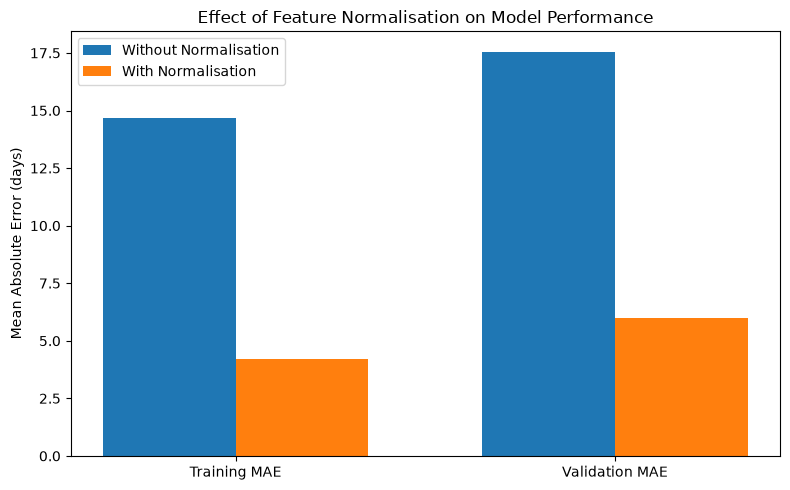

In [15]:

import matplotlib.pyplot as plt

metrics = ["Training MAE", "Validation MAE"]

without_norm = [14.68, 17.56]
with_norm = [4.19, 5.99]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, without_norm, width,
        label="Without Normalisation")

plt.bar(x + width/2, with_norm, width,
        label="With Normalisation")

plt.xticks(x, metrics)
plt.ylabel("Mean Absolute Error (days)")
plt.title("Effect of Feature Normalisation on Model Performance")
plt.legend()
plt.tight_layout()
plt.show()



### Observation – Final Comparison of Normalised and Unnormalised Training

The two neural network experiments were successfully completed using identical architectures and training configurations, with feature normalisation being the primary difference.

The model trained without normalisation achieved a training MAE of 14.68 days and validation MAE of 17.56 days.

The model trained with normalisation achieved a training MAE of 4.19 days and validation MAE of 5.99 days.

This represents a 71.46% reduction in training MAE and a 65.89% reduction in validation MAE.

The bar chart clearly demonstrates the improvement in model performance after applying feature standardisation.

Based on these experimental results, feature normalisation is selected for integration into the actual neural network training pipeline.



## Phase 9 – Final Conclusion

Feature normalisation was successfully implemented and integrated into the battery prediction training pipeline.

The training mean and standard deviation were calculated using only the training dataset and reused for validation data.

Two neural network experiments were conducted using identical training configurations.

- Without normalisation: Training MAE = 14.68 days, Validation MAE = 17.56 days.
- With normalisation: Training MAE = 4.19 days, Validation MAE = 5.99 days.

The normalised model achieved a 71.46% reduction in training MAE and a 65.89% reduction in validation MAE.

The normalisation implementation was integrated into train.py and successfully executed.

The trained model weights were saved in model/model.pt, while model/config.json stores the architecture, feature names, training mean, standard deviation and validation MAE.

Therefore, feature normalisation is adopted as part of the final model training pipeline.
